### IMPORTS

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import xgboost as xgb
import numpy as np
import seaborn as sns
import pandas as pd

from arch import arch_model

from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

DATA_DIR = Path("FRED")
RESULTS_PATH = Path("results/dl_models_results.json")
TRAIN_FRACTION = 0.8
VALIDATION_FRACTION = 0.1
model_results = {}

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Using device: {DEVICE}")

Using device: cuda


### DATA LOADING

In [2]:
def load_data(file_name, BASE_DIR=DATA_DIR):
    file_path = BASE_DIR / file_name
    data = pd.read_csv(file_path)
    return data

In [3]:
usdinr = load_data("DEXINUS.csv")
usdjpy = load_data("DEXJPUS.csv")
usdeur = load_data("DEXUSEU.csv")
repo_rate = load_data("DFF.csv")
treasury_yield = load_data("DGS10.csv")
commodity_prices = load_data("commodity_futures.csv")
india_vix = load_data("VIX_History.csv")
nifty50 = load_data("NIFTY50_scraped.csv")
nifty50pepb = load_data("NIFTY 50 - HistoricalPE_PBDIV_Data.csv")
niftybank = load_data("NIFTY BANK_Data.csv")
niftybankpepb = load_data("NIFTY BANK - HistoricalPE_PBDIV_Data.csv")
india_gold = load_data("Gold price INR.csv")
sap500 = load_data("sap500.csv")

### BASIC EXPLORATION

In [4]:
print("USD/INR Data:")
print(usdinr.head())
print("USD/JPY Data:")
print(usdjpy.head())
print("USD/EUR Data:")
print(usdeur.head())
print("Repo Rate Data:")
print(repo_rate.head())
print("Treasury Yield Data:")
print(treasury_yield.head())
print("Commodity Prices Data:")
print(commodity_prices.head())
print("India VIX Data:")
print(india_vix.head())
print("Nifty 50 Data:")
print(nifty50.head())
print("Nifty Bank Data:")
print(niftybank.head())
print("S&P 500 Data:")
print(sap500.head())

USD/INR Data:
  observation_date  DEXINUS
0       1973-01-02     8.02
1       1973-01-03     8.02
2       1973-01-04     8.00
3       1973-01-05     8.01
4       1973-01-08     8.00
USD/JPY Data:
  observation_date  DEXJPUS
0       1971-01-04   357.73
1       1971-01-05   357.81
2       1971-01-06   357.86
3       1971-01-07   357.87
4       1971-01-08   357.82
USD/EUR Data:
  observation_date  DEXUSEU
0       1999-01-04   1.1812
1       1999-01-05   1.1760
2       1999-01-06   1.1636
3       1999-01-07   1.1672
4       1999-01-08   1.1554
Repo Rate Data:
  observation_date   DFF
0       1954-07-01  1.13
1       1954-07-02  1.25
2       1954-07-03  1.25
3       1954-07-04  1.25
4       1954-07-05  0.88
Treasury Yield Data:
  observation_date  DGS10
0       1962-01-02   4.06
1       1962-01-03   4.03
2       1962-01-04   3.99
3       1962-01-05   4.02
4       1962-01-08   4.03
Commodity Prices Data:
         Date  NATURAL GAS   GOLD  WTI CRUDE  BRENT CRUDE  SOYBEANS    CORN  \
0  2000-0

In [5]:
print("\033[1;32m" + "="*30 + " USD/INR Data: " + "="*30 + "\033[0m")
print(usdinr.info())
print(usdinr.describe())
print("\033[1;32m" + "="*30 + " USD/JPY Data: " + "="*30 + "\033[0m")
print(usdjpy.info())
print(usdjpy.describe())
print("\033[1;32m" + "="*30 + " USD/EUR Data: " + "="*30 + "\033[0m")
print(usdeur.info())
print(usdeur.describe())
print("\033[1;32m" + "="*30 + " Repo Rate Data: " + "="*30 + "\033[0m")
print(repo_rate.info())
print(repo_rate.describe())
print("\033[1;32m" + "="*30 + " Treasury Yield Data: " + "="*30 + "\033[0m")
print(treasury_yield.info())
print(treasury_yield.describe())
print("\033[1;32m" + "="*30 + " Commodity Prices Data: " + "="*30 + "\033[0m")
print(commodity_prices.info())
print(commodity_prices.describe())
print("\033[1;32m" + "="*30 + " India VIX Data: " + "="*30 + "\033[0m")
print(india_vix.info())
print(india_vix.describe())
print("\033[1;32m" + "="*30 + " Nifty 50 Data: " + "="*30 + "\033[0m")
print(nifty50.info())
print(nifty50.describe())
print("\033[1;32m" + "="*30 + " Nifty Bank Data: " + "="*30 + "\033[0m")
print(niftybank.info())
print(niftybank.describe())
print("\033[1;32m" + "="*30 + " S&P 500 Data: " + "="*30 + "\033[0m")
print(sap500.info())
print(sap500.describe())

============================== USD/INR Data: ==============================
<class 'pandas.DataFrame'>
RangeIndex: 13999 entries, 0 to 13998
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  13999 non-null  str    
 1   DEXINUS           13449 non-null  float64
dtypes: float64(1), str(1)
memory usage: 355.6 KB
None
            DEXINUS
count  13449.000000
mean      38.951964
std       24.830751
min        7.190000
25%       12.620000
50%       42.500000
75%       55.520000
max       96.820000
============================== USD/JPY Data: ==============================
<class 'pandas.DataFrame'>
RangeIndex: 14520 entries, 0 to 14519
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  14520 non-null  str    
 1   DEXJPUS           13951 non-null  float64
dtypes: float64(1), str(1)
memory usage: 36

### SET INDEXES

In [6]:
usdinr["observation_date"] = pd.to_datetime(usdinr["observation_date"])
usdinr = usdinr.set_index("observation_date")

usdjpy["observation_date"] = pd.to_datetime(usdjpy["observation_date"])
usdjpy = usdjpy.set_index("observation_date")

usdeur["observation_date"] = pd.to_datetime(usdeur["observation_date"])
usdeur = usdeur.set_index("observation_date")

repo_rate["observation_date"] = pd.to_datetime(repo_rate["observation_date"])
repo_rate = repo_rate.set_index("observation_date")

treasury_yield["observation_date"] = pd.to_datetime(treasury_yield["observation_date"])
treasury_yield = treasury_yield.set_index("observation_date")

commodity_prices["Date"] = pd.to_datetime(commodity_prices["Date"])
commodity_prices = commodity_prices.set_index("Date")

india_vix["Date"] = pd.to_datetime(india_vix["DATE"])
india_vix = india_vix.set_index("Date")

nifty50["Date"] = pd.to_datetime(nifty50["Date"])
nifty50 = nifty50.set_index("Date")

nifty50pepb["Date"] = pd.to_datetime(nifty50pepb["Date"])
nifty50pepb = nifty50pepb.set_index("Date")

niftybank["Date"] = pd.to_datetime(niftybank["Date"])
niftybank = niftybank.set_index("Date")

niftybankpepb["Date"] = pd.to_datetime(niftybankpepb["Date"])
niftybankpepb = niftybankpepb.set_index("Date")

india_gold["Date"] = pd.to_datetime(india_gold["Date"], format="%d/%m/%Y")
india_gold = india_gold.set_index("Date")

sap500["Date"] = pd.to_datetime(sap500["Date"])
sap500 = sap500.set_index("Date")

### MERGE INDEXES AND DATAFRAMES AND ADD FEATURES

In [ ]:
## MERGE INDEXES AND DATAFRAMES

# USDINR
full_df = usdinr.copy()

# GLOBAL DATA
full_df["jpy"] = usdjpy["DEXJPUS"]
full_df["eur"] = usdeur["DEXUSEU"]
full_df["repo_rate"] = repo_rate["DFF"]
full_df["treasury_yield"] = treasury_yield["DGS10"]

# COMMODITY PRICES GLOBALLY
full_df["gold"] = commodity_prices["GOLD"]
full_df["wti_crude"] = commodity_prices["WTI CRUDE"]
full_df["brent_crude"] = commodity_prices["BRENT CRUDE"]
full_df["soybeans"] = commodity_prices["SOYBEANS"]
full_df["corn"] = commodity_prices["CORN"]
full_df["copper"] = commodity_prices["COPPER"]
full_df["silver"] = commodity_prices["SILVER"]
full_df["low_sulphur_gas_oil"] = commodity_prices["LOW SULPHUR GAS OIL"]
full_df["live_cattle"] = commodity_prices["LIVE CATTLE"]
full_df["soybean_oil"] = commodity_prices["SOYBEAN OIL"]
full_df["aluminium"] = commodity_prices["ALUMINIUM"]
full_df["soybean_meal"] = commodity_prices["SOYBEAN MEAL"]
full_df["zinc"] = commodity_prices["ZINC"]
full_df["uls_diesel"] = commodity_prices["ULS DIESEL"]
full_df["nickel"] = commodity_prices["NICKEL"]
full_df["wheat"] = commodity_prices["WHEAT"]
full_df["sugar"] = commodity_prices["SUGAR"]
# full_df["gasoline"] = commodity_prices["GASOLINE"]
full_df["coffee"] = commodity_prices["COFFEE"]
full_df["lean_hogs"] = commodity_prices["LEAN HOGS"]
full_df["hrw_wheat"] = commodity_prices["HRW WHEAT"]
full_df["cotton"] = commodity_prices["COTTON"]

# INDIA DATA
full_df["india_vix_open"] = india_vix["OPEN"]
full_df["india_vix_high"] = india_vix["HIGH"]
full_df["india_vix_low"] = india_vix["LOW"]
full_df["india_vix_close"] = india_vix["CLOSE"]
full_df["nifty50_open"] = nifty50["Open"]
full_df["nifty50_high"] = nifty50["High"]
full_df["nifty50_low"] = nifty50["Low"]
full_df["nifty50_close"] = nifty50["Close"]
full_df["nifty50_pe"] = nifty50pepb["P/E"]
full_df["nifty50_pb"] = nifty50pepb["P/B"]
full_df["nifty50_div_yield"] = nifty50pepb["Div Yield %"]
# full_df["niftybank_open"] = niftybank["Open"]
# full_df["niftybank_high"] = niftybank["High"]
# full_df["niftybank_low"] = niftybank["Low"]
full_df["niftybank_close"] = niftybank["Close"]
full_df["niftybank_pe"] = niftybankpepb["P/E"]
full_df["niftybank_pb"] = niftybankpepb["P/B"]
full_df["niftybank_div_yield"] = niftybankpepb["Div Yield %"]
full_df["india_gold"] = india_gold["INR"]

# US DATA
full_df["sp500_open"] = sap500["Open"]
full_df["sp500_high"] = sap500["High"]
full_df["sp500_low"] = sap500["Low"]
full_df["sp500_close"] = sap500["Close"]
full_df["sp500_volume"] = sap500["Volume"]

print(full_df.head())


                  DEXINUS     jpy  eur  repo_rate  treasury_yield  gold  \
observation_date                                                          
1973-01-02           8.02  301.39  NaN       6.00            6.43   NaN   
1973-01-03           8.02  301.43  NaN       5.50            6.42   NaN   
1973-01-04           8.00  301.20  NaN       5.75            6.40   NaN   
1973-01-05           8.01  301.30  NaN       5.75            6.42   NaN   
1973-01-08           8.00  302.21  NaN       5.63            6.43   NaN   

                  wti_crude  brent_crude  soybeans  corn  ...  \
observation_date                                          ...   
1973-01-02              NaN          NaN       NaN   NaN  ...   
1973-01-03              NaN          NaN       NaN   NaN  ...   
1973-01-04              NaN          NaN       NaN   NaN  ...   
1973-01-05              NaN          NaN       NaN   NaN  ...   
1973-01-08              NaN          NaN       NaN   NaN  ...   

                  

### DATA CLEANING

In [8]:
# Keep observations from 1 January 2000 onward before handling missing values.
full_df = full_df.loc[
    full_df.index.to_series().between("2000-01-01", "2021-12-31")
].copy()

print(f"Shape after restricting data to 2000 onward: {full_df.shape}")
missing_summary = (
    full_df.isna()
    .sum()
    .sort_values(ascending=False)
    .rename("missing_values")
    .to_frame()
    .assign(
        missing_percent=lambda frame: (
            frame["missing_values"] / len(full_df) * 100
        ).round(2)
    )
)
missing_summary = missing_summary[missing_summary["missing_values"] > 0]

print("Columns with missing values:")
display(missing_summary)

Shape after restricting data to 2000 onward: (5740, 47)
Columns with missing values:


,missing_values,missing_percent
niftybank_pb,291,5.07
nifty50_pe,291,5.07
niftybank_pe,291,5.07
niftybank_div_yield,291,5.07
nifty50_pb,291,5.07
nifty50_div_yield,291,5.07
nifty50_open,290,5.05
nifty50_close,290,5.05
nifty50_high,290,5.05
niftybank_close,290,5.05


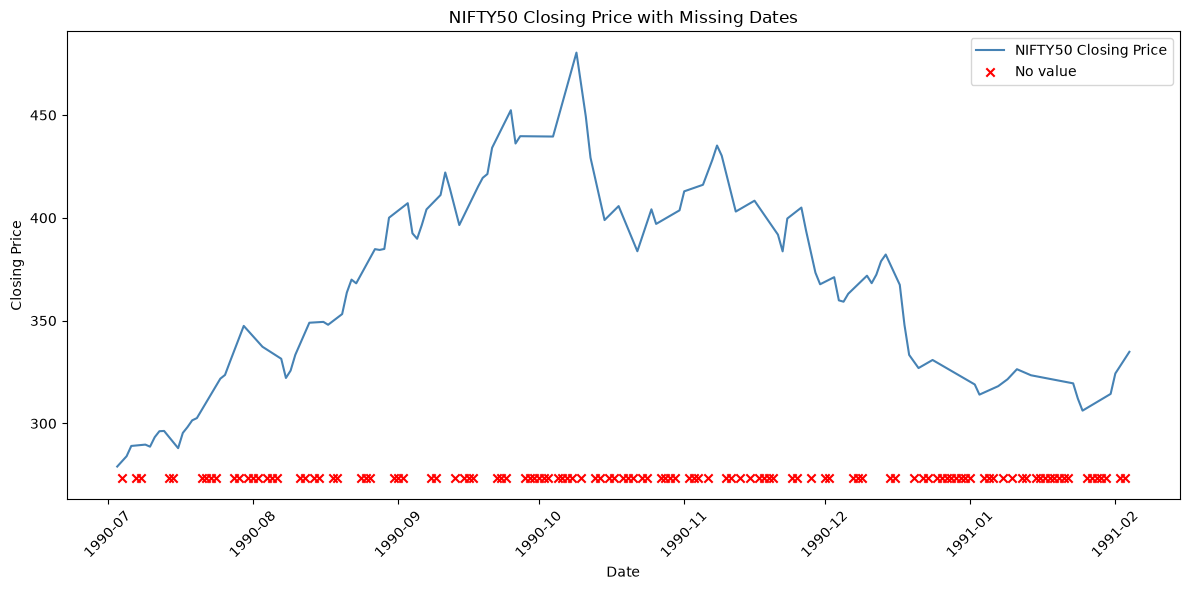

In [9]:
period = nifty50.sort_index().iloc[:100]

daily_data = period["Close"].reindex(
    pd.date_range(period.index.min(), period.index.max(), freq="D")
)[:300]

missing_dates = daily_data.index[daily_data.isna()]
available_data = daily_data.dropna()

plt.figure(figsize=(12, 6))
plt.plot(
    available_data.index,
    available_data,
    color="steelblue",
    label="NIFTY50 Closing Price",
)

baseline = available_data.min() * 0.98
plt.scatter(
    missing_dates,
    [baseline] * len(missing_dates),
    color="red",
    marker="x",
    label="No value",
    zorder=3,
)

plt.title("NIFTY50 Closing Price with Missing Dates")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NIFTY50 null dates: 290


,date,day,day_name,month,month_name,week,year,DEXINUS
0,2000-01-26,26,Wednesday,1,January,4,2000,43.65
1,2000-03-17,17,Friday,3,March,11,2000,43.65
2,2000-03-20,20,Monday,3,March,12,2000,43.63
3,2000-04-14,14,Friday,4,April,15,2000,43.75
4,2000-04-21,21,Friday,4,April,16,2000,43.70
...,...,...,...,...,...,...,...,...
285,2021-08-19,19,Thursday,8,August,33,2021,74.38
286,2021-09-10,10,Friday,9,September,36,2021,73.52
287,2021-10-15,15,Friday,10,October,41,2021,74.98
288,2021-11-05,5,Friday,11,November,44,2021,74.22


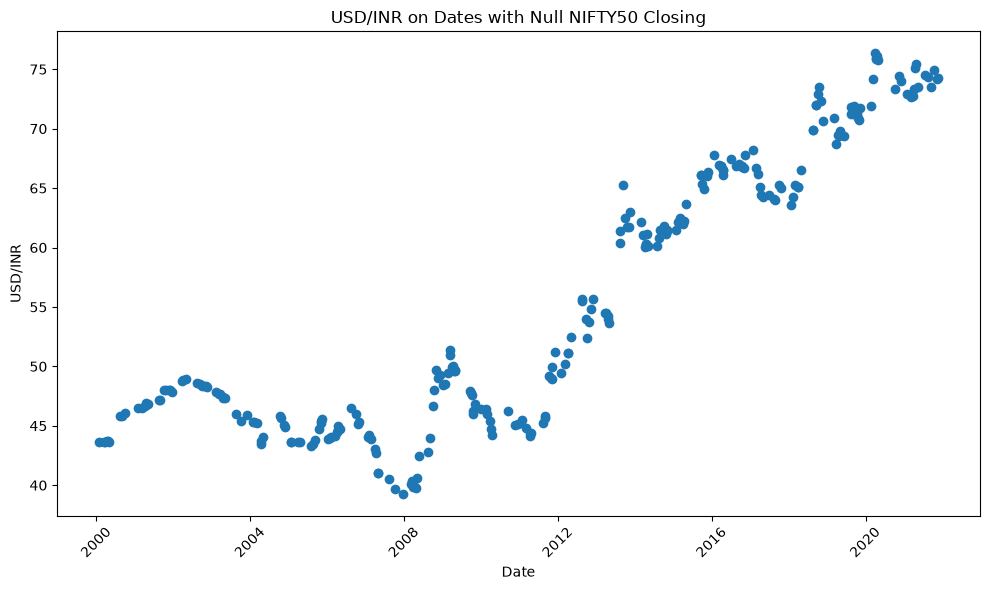

In [10]:
## DATES WHERE NIFTY50 CLOSING IS NULL
missing_nifty50 = full_df.loc[full_df["nifty50_close"].isnull()].copy()
missing_dates = missing_nifty50.index
iso_calendar = missing_dates.isocalendar()

missing_nifty50_table = pd.DataFrame(
    {
        "date": missing_dates,
        "day": missing_dates.day,
        "day_name": missing_dates.day_name(),
        "month": missing_dates.month,
        "month_name": missing_dates.month_name(),
        "week": iso_calendar.week.to_numpy(),
        "year": iso_calendar.year.to_numpy(),
        "DEXINUS": missing_nifty50["DEXINUS"].to_numpy(),
    }
)

print(f"NIFTY50 null dates: {len(missing_nifty50_table)}")
display(missing_nifty50_table)

plt.figure(figsize=(10, 6))
plt.scatter(missing_dates, missing_nifty50["DEXINUS"])
plt.title("USD/INR on Dates with Null NIFTY50 Closing")
plt.xlabel("Date")
plt.ylabel("USD/INR")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
missing_nifty50_table.groupby("day_name").size().sort_values(ascending=False).rename("count").to_frame()

,count
day_name,
Friday,75
Monday,57
Thursday,56
Tuesday,51
Wednesday,51


In [12]:
missing_nifty50_table.groupby("year").size().sort_values(ascending=False).rename("count").to_frame()

,count
year,
2009,20
2014,18
2019,17
2008,16
2018,15
2016,15
2012,14
2015,14
2006,13


We see that nifty data has discontinuity which can be due to holidays \

and other data may have holidays too \

so we will use forward filling of data

In [13]:
## forward fill the missing values
for col in full_df.columns:
    full_df[col] = full_df[col].ffill()

### MORE FEATURES

In [14]:
# Technical Indicators
full_df["usdinr_ma_5"] = full_df["DEXINUS"].rolling(window=5, min_periods=1).mean()
full_df["usdinr_ma_10"] = full_df["DEXINUS"].rolling(window=10, min_periods=1).mean()
full_df["usdinr_ma_30"] = full_df["DEXINUS"].rolling(window=30, min_periods=1).mean()
full_df["usdinr_ma_50"] = full_df["DEXINUS"].rolling(window=50, min_periods=1).mean()
full_df["usdinr_ma_100"] = full_df["DEXINUS"].rolling(window=100, min_periods=1).mean()
full_df["usdinr_ema_5"] = full_df["DEXINUS"].ewm(span=5, adjust=False).mean()
full_df["usdinr_ema_10"] = full_df["DEXINUS"].ewm(span=10, adjust=False).mean()
full_df["usdinr_ema_30"] = full_df["DEXINUS"].ewm(span=30, adjust=False).mean()
full_df["usdinr_ema_50"] = full_df["DEXINUS"].ewm(span=50, adjust=False).mean()
full_df["usdinr_ema_100"] = full_df["DEXINUS"].ewm(span=100, adjust=False).mean()
full_df["returns"] = full_df["DEXINUS"].pct_change()
full_df["returns_5day"] = full_df["returns"].rolling(window=5, min_periods=1).mean()
full_df["returns_10day"] = full_df["returns"].rolling(window=10, min_periods=1).mean()
full_df["log_returns"] = np.log(full_df["DEXINUS"] / full_df["DEXINUS"].shift(1))
full_df["log_returns_5day"] = full_df["log_returns"].rolling(window=5, min_periods=1).mean()
full_df["volatility_5day"] = full_df["log_returns"].rolling(window=5, min_periods=1).std()
threshold = 0.002  # 0.2% return threshold
pct_change_1d = full_df["DEXINUS"].pct_change(periods=1)
full_df["trade_signal"] = np.where(
    pct_change_1d > threshold, 1,
    np.where(pct_change_1d < -threshold, -1, 0)
)
full_df["trend_1day"] = (
    (full_df["DEXINUS"].pct_change(periods=1) > 0)
    .astype(int)
)
full_df["trend_5day"] = (
    (full_df["DEXINUS"].pct_change(periods=5) > 0)
    .astype(int)
)
# Calendar features for day-of-week and seasonal effects
full_df["day_of_week"] = full_df.index.dayofweek
full_df["month"] = full_df.index.month

### FINAL CLEANING

In [15]:
# Keep observations from 1 January 2000 onward before handling missing values.
full_df = full_df.loc[
    full_df.index.to_series().between("2000-01-01", "2021-12-31")
].copy()

print(f"Shape after restricting data to 2000 onward: {full_df.shape}")
missing_summary = (
    full_df.isna()
    .sum()
    .sort_values(ascending=False)
    .rename("missing_values")
    .to_frame()
    .assign(
        missing_percent=lambda frame: (
            frame["missing_values"] / len(full_df) * 100
        ).round(2)
    )
)
missing_summary = missing_summary[missing_summary["missing_values"] > 0]

print("Columns with missing values:")
display(missing_summary)

Shape after restricting data to 2000 onward: (5740, 68)
Columns with missing values:


,missing_values,missing_percent
volatility_5day,2,0.03
wti_crude,1,0.02
gold,1,0.02
brent_crude,1,0.02
returns,1,0.02
log_returns_5day,1,0.02
log_returns,1,0.02
returns_5day,1,0.02
copper,1,0.02
uls_diesel,1,0.02


In [16]:
# Final cleaning after all technical features have been created.
full_df = full_df.loc[
    full_df.index.to_series().between("2000-01-01", "2021-12-31")
].sort_index().copy()

# Convert placeholder strings before filling and dropping missing values.
numeric_columns = [
    "nifty50_div_yield",
    "niftybank_div_yield",
    "niftybank_pe",
]
for column in numeric_columns:
    full_df[column] = pd.to_numeric(
        full_df[column].replace({"-": np.nan, "": np.nan}),
        errors="coerce",
    )


In [17]:

# Predict today's log return using information available through the previous day.
target_col = "trend_1day"
feature_cols = full_df.columns.difference([target_col, "trade_signal"])
full_df[feature_cols] = full_df[feature_cols].ffill(limit=5)
full_df[feature_cols] = full_df[feature_cols].shift(1)

# Do not fill the target or use future observations to create features.
full_df = full_df.dropna()
feature_cols = full_df.columns.difference([target_col, "trade_signal"])

print(f"Target column: {target_col}")
print(f"Shape after final cleaning: {full_df.shape}")
print(f"Remaining missing values: {int(full_df.isna().sum().sum())}")


Target column: trend_1day
Shape after final cleaning: (5737, 68)
Remaining missing values: 0


### ADD GARCH FEATURES

In [18]:
# GARCH-based volatility features
returns = (full_df["log_returns"] * 100).dropna()

models = {
    "garch": arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1, dist="t").fit(disp="off"),
    "egarch": arch_model(returns, mean="Constant", vol="EGARCH", p=1, o=1, q=1, dist="t").fit(disp="off"),
    "figarch": arch_model(returns, mean="Constant", vol="FIGARCH", p=1, q=1, dist="t").fit(disp="off"),
    "aparch": arch_model(returns, mean="Constant", vol="APARCH", p=1, o=1, q=1, dist="t").fit(disp="off"),
}

for model_name, model in models.items():
    full_df[f"garch_{model_name}_volatility"] = (
        model.conditional_volatility / 100
    ).reindex(full_df.index).shift(1)

feature_cols = full_df.columns.difference([target_col, "trade_signal"])
full_df = full_df.dropna(subset=feature_cols)
feature_cols = full_df.columns.difference([target_col, "trade_signal"])
print("GARCH features added:")
print([column for column in feature_cols if column.startswith("garch_")])


GARCH features added:
['garch_aparch_volatility', 'garch_egarch_volatility', 'garch_figarch_volatility', 'garch_garch_volatility']


### COORELATION MATRIX

<Axes: >

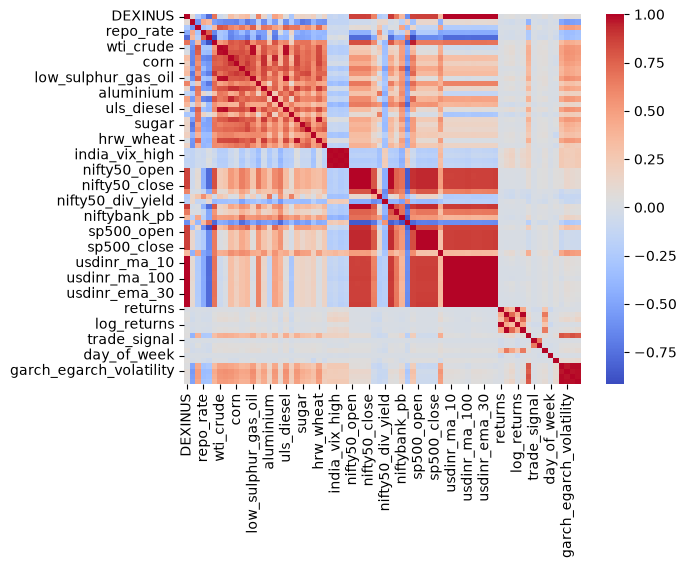

In [19]:
# CORRELATION ANALYSIS
correlation_matrix = full_df.corr()
sns.heatmap(correlation_matrix, fmt=".2f", cmap="coolwarm", cbar=True)

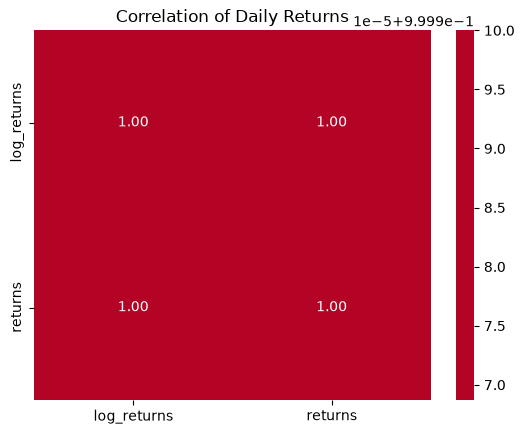

In [20]:
return_cols = [
    "log_returns",
    "returns",
    "DCOILWTICO",
    "sap500",
    "DEXUSEU",
    "DEXJPUS",
    "VIX",
]

return_data = full_df[[c for c in return_cols if c in full_df.columns]].copy()
return_data = return_data.pct_change().dropna()

sns.heatmap(
    return_data.corr(method="pearson"),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation of Daily Returns")
plt.show()


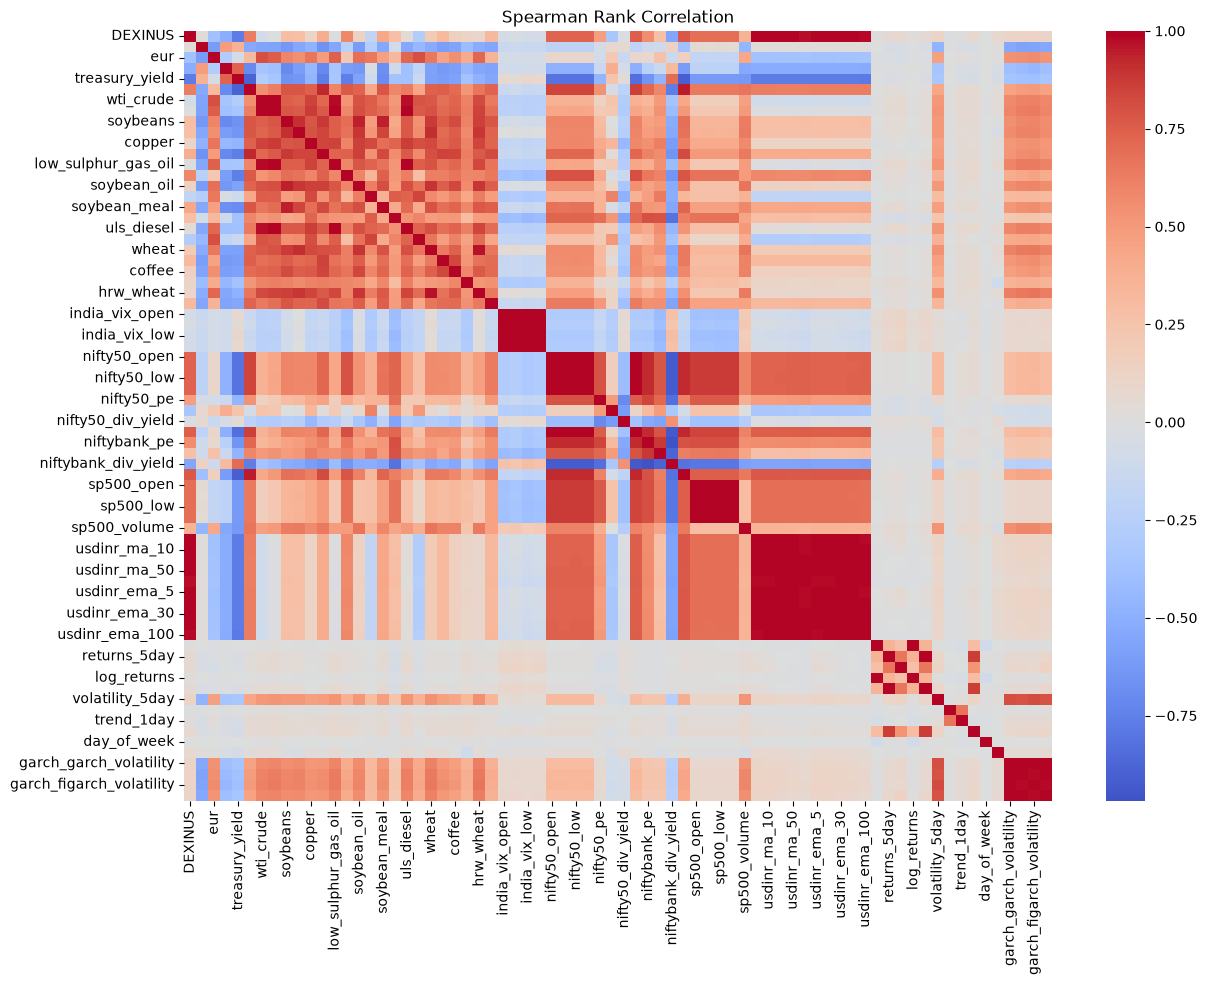

In [21]:
spearman_corr = full_df.corr(method="spearman")

plt.figure(figsize=(14, 10))
sns.heatmap(spearman_corr, cmap="coolwarm", center=0)
plt.title("Spearman Rank Correlation")
plt.show()

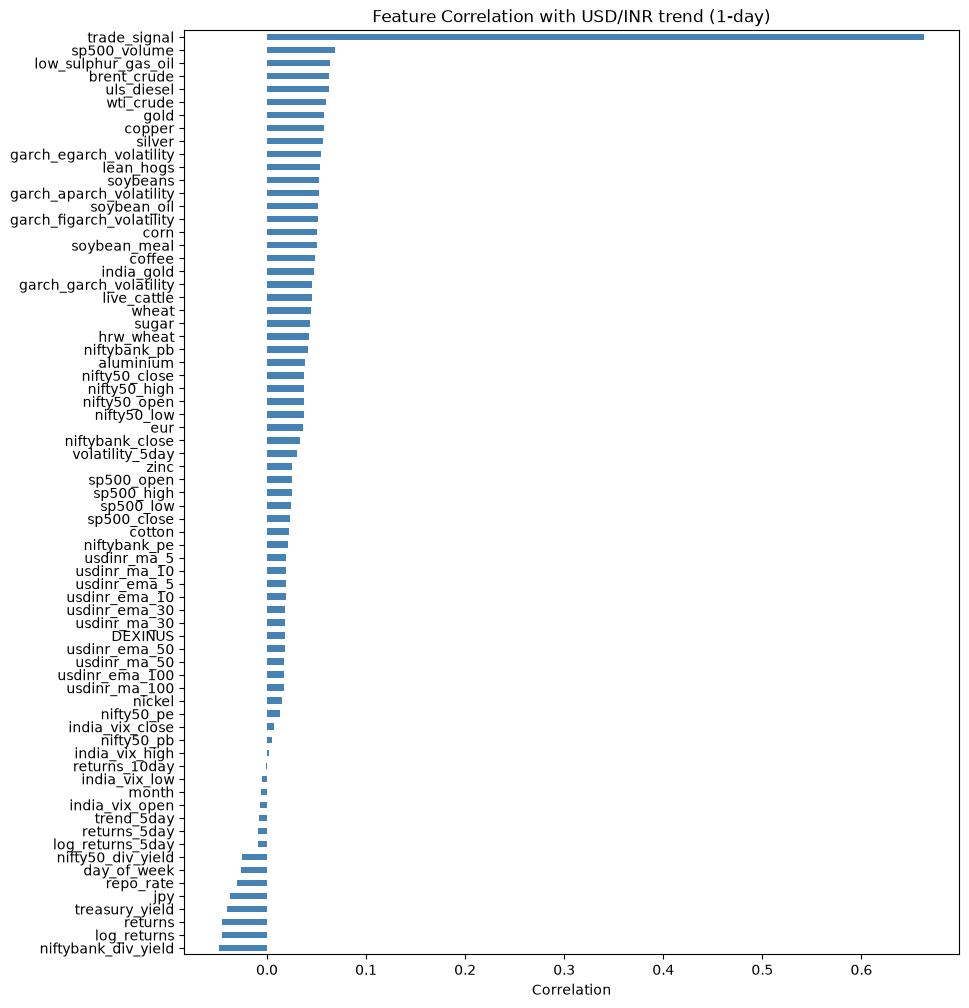

In [22]:
target_corr = (
    full_df.corr()[target_col]
    .drop(target_col)
    .sort_values()
)

target_corr.plot(kind="barh", figsize=(10, 12), color="steelblue")
plt.title("Feature Correlation with USD/INR trend (1-day)")
plt.xlabel("Correlation")
plt.show()

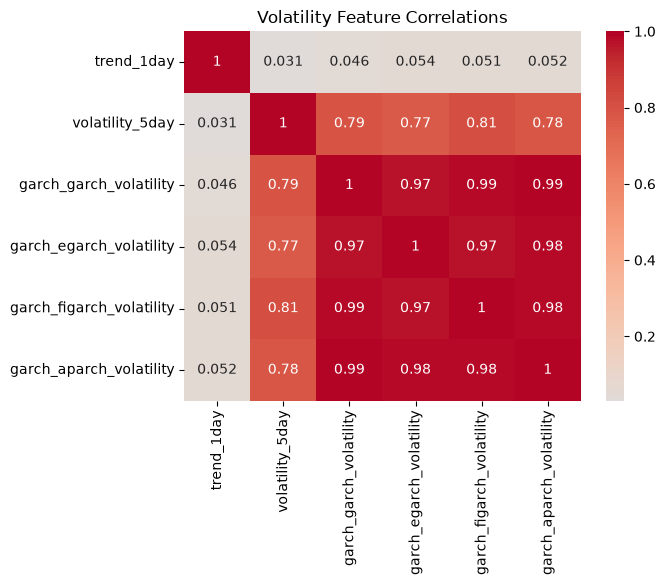

In [23]:
volatility_cols = [
    c for c in full_df.columns
    if "volatility" in c.lower() or "garch" in c.lower()
]

volatility_corr = full_df[
    [target_col] + volatility_cols
].corr()

sns.heatmap(volatility_corr, annot=True, cmap="coolwarm", center=0)
plt.title("Volatility Feature Correlations")
plt.show()

### ALL FEATURES

In [24]:
features_list = [
    "DEXINUS",
    "jpy",
    "eur",
    "repo_rate",
    "treasury_yield",
    
    # COMMODITY PRICES GLOBALLY
    "gold",
    "wti_crude",
    "brent_crude",
    "soybeans",
    "corn",
    "copper",
    "silver",
    "low_sulphur_gas_oil",
    "live_cattle",
    "soybean_oil",
    "aluminium",
    "soybean_meal",
    "zinc",
    "uls_diesel",
    "nickel",
    "wheat",
    "sugar",
    "coffee",
    "lean_hogs",
    "hrw_wheat",
    "cotton",
    
    # INDIA DATA
    "india_vix_open",
    "india_vix_high",
    "india_vix_low",
    "india_vix_close",
    "nifty50_open",
    "nifty50_high",
    "nifty50_low",
    "nifty50_close",
    "nifty50_pe",
    "nifty50_pb",
    "nifty50_div_yield",
    "niftybank_close",
    "niftybank_pe",
    "niftybank_pb",
    "niftybank_div_yield",
    "india_gold",
    "trend_1day",
    "trend_5day",
    
    # US DATA
    "sp500_open",
    "sp500_high",
    "sp500_low",
    "sp500_close",
    "sp500_volume",
    
    # Technical Indicators
    "usdinr_ma_5",
    "usdinr_ma_10",
    "usdinr_ma_30",
    "usdinr_ma_50",
    "usdinr_ma_100",
    "usdinr_ema_5",
    "usdinr_ema_10",
    "usdinr_ema_30",
    "usdinr_ema_50",
    "usdinr_ema_100",
    "returns",
    "returns_5day",
    "returns_10day",
    "log_returns",
    "log_returns_5day",
    "volatility_5day",
    "garch_garch_volatility",
    "garch_egarch_volatility",
    "garch_figarch_volatility",
    "garch_aparch_volatility",
]

In [25]:
full_df.shape

(5736, 72)

### DATALOADERS

In [26]:
class CustomDataLoader:
    def __init__(
        self,
        data,
        feature_cols,
        target_col,
        sequence_length=30,
        batch_size=64,
        train_length=0.8,
        val_length=0.1,
        scaler=StandardScaler,
        binary_output=True,
    ):
        self.data = data.sort_index().copy()
        self.feature_cols = list(feature_cols)
        self.target_col = target_col
        self.sequence_length = sequence_length
        self.batch_size = batch_size
        self.binary_output = binary_output

        features = self.data[self.feature_cols].to_numpy(dtype=np.float32)
        targets = self.data[target_col].to_numpy(dtype=np.float32)

        self.train_end = self._get_length(train_length, len(self.data))
        self.val_end = self.train_end + self._get_length(
            val_length, len(self.data)
        )

        if self.val_end >= len(self.data):
            raise ValueError("Training and validation lengths exceed dataset size.")

        self.feature_scaler = scaler()
        self.feature_scaler.fit(features[:self.train_end])
        features = self.feature_scaler.transform(features).astype(np.float32)

        if binary_output:
            # Required for BCEWithLogitsLoss.
            targets = targets.astype(np.float32)
        else:
            # Required for continuous regression targets.
            self.target_scaler = scaler()
            self.target_scaler.fit(targets[:self.train_end, None])
            targets = self.target_scaler.transform(
                targets[:, None]
            ).astype(np.float32).ravel()

        sequences = []
        sequence_targets = []
        sequence_indices = []

        for index in range(sequence_length, len(self.data)):
            sequences.append(features[index - sequence_length:index])
            sequence_targets.append(targets[index])
            sequence_indices.append(index)

        self.sequences = torch.tensor(
            np.asarray(sequences), dtype=torch.float32
        )
        self.targets = torch.tensor(
            np.asarray(sequence_targets), dtype=torch.float32
        ).unsqueeze(1)
        self.sequence_indices = np.asarray(sequence_indices)

    @staticmethod
    def _get_length(length, total_length):
        if isinstance(length, float):
            return int(total_length * length)
        return int(length)

    def _make_loader(self, mask, shuffle=False):
        dataset = TensorDataset(
            self.sequences[mask],
            self.targets[mask],
        )

        return DataLoader(
            dataset,
            batch_size=self.batch_size,
            shuffle=shuffle,
            pin_memory=DEVICE.type == "cuda",
        )

    def get_loaders(self):
        train_mask = self.sequence_indices < self.train_end
        val_mask = (
            (self.sequence_indices >= self.train_end)
            & (self.sequence_indices < self.val_end)
        )
        test_mask = self.sequence_indices >= self.val_end

        return {
            "train": self._make_loader(train_mask, shuffle=True),
            "validation": self._make_loader(val_mask),
            "test": self._make_loader(test_mask),
        }

### FULL TRAINER CLASS

In [27]:
class ModelTrainer:
    def __init__(self, model, optimizer, criterion, device=DEVICE,
                 test_data_loader=None, train_data_loader=None,
                 validation_data_loader=None, max_grad_norm=None):
        self.model = model.to(device)
        self.optimizer = optimizer
        self.criterion = criterion
        self.device = device
        self.test_data_loader = test_data_loader
        self.validation_data_loader = validation_data_loader
        self.train_data_loader = train_data_loader
        self.max_grad_norm = max_grad_norm

    def train_epoch(self):
        self.model.train()
        total_loss = 0.0
        for inputs, targets in self.train_data_loader:
            inputs, targets = inputs.to(self.device), targets.to(self.device)
            self.optimizer.zero_grad()
            outputs = self.model(inputs)
            loss = self.criterion(outputs, targets)
            loss.backward()
            if self.max_grad_norm is not None:
                torch.nn.utils.clip_grad_norm_(
                    self.model.parameters(), self.max_grad_norm
                )
            self.optimizer.step()
            total_loss += loss.item() * inputs.size(0)
        return total_loss / len(self.train_data_loader.dataset)

    def evaluate(self):
        self.model.eval()
        total_loss = 0.0
        with torch.no_grad():
            for inputs, targets in self.test_data_loader:
                inputs, targets = inputs.to(self.device), targets.to(self.device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, targets)
                total_loss += loss.item() * inputs.size(0)
        return total_loss / len(self.test_data_loader.dataset)

    def validate(self):
        self.model.eval()
        total_loss = 0.0
        with torch.no_grad():
            for inputs, targets in self.validation_data_loader:
                inputs, targets = inputs.to(self.device), targets.to(self.device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, targets)
                total_loss += loss.item() * inputs.size(0)
        return total_loss / len(self.validation_data_loader.dataset)

    def train_and_predict_sequential(self, data_loader):
        predictions = []
        actuals = []
        
        for inputs, targets in data_loader:
            inputs, targets = inputs.to(self.device), targets.to(self.device)
            
            # Predict first
            self.model.eval()
            with torch.no_grad():
                outputs = self.model(inputs)
                predictions.append(outputs.detach().cpu().numpy())
                actuals.append(targets.cpu().numpy())
            
            # Then train
            self.model.train()
            self.optimizer.zero_grad()
            train_outputs = self.model(inputs)
            loss = self.criterion(train_outputs, targets)
            loss.backward()
            if self.max_grad_norm is not None:
                torch.nn.utils.clip_grad_norm_(
                    self.model.parameters(), self.max_grad_norm
                )
            self.optimizer.step()
            
        import numpy as np
        return {
            "predictions": np.concatenate(predictions).ravel(),
            "targets": np.concatenate(actuals).ravel()
        }


### MODEL EVALUATOR

In [28]:
class ModelEvaluator:
    def __init__(self, model, device=DEVICE, binary_output=True):
        self.model = model.to(device)
        self.device = device
        self.binary_output = binary_output

    def predict(self, data_loader, threshold=0.5):
        self.model.eval()

        outputs = []
        targets = []

        with torch.no_grad():
            for inputs, batch_targets in data_loader:
                inputs = inputs.to(self.device)
                batch_outputs = self.model(inputs)
                outputs.append(batch_outputs.detach().cpu().numpy())
                targets.append(batch_targets.numpy())

        raw_outputs = np.concatenate(outputs).ravel()
        y_true = np.concatenate(targets).ravel()

        if self.binary_output:
            probabilities = 1 / (1 + np.exp(-raw_outputs))
            predictions = (probabilities >= threshold).astype(int)
        else:
            probabilities = None
            predictions = raw_outputs

        return {
            "targets": y_true,
            "outputs": raw_outputs,
            "probabilities": probabilities,
            "predictions": predictions,
        }

    def get_scores(self, data_loader, threshold=0.5):
        result = self.predict(data_loader, threshold)
        y_true = result["targets"]
        y_pred = result["predictions"]

        if self.binary_output:
            scores = {
                "accuracy": accuracy_score(y_true, y_pred),
                "precision": precision_score(y_true, y_pred, zero_division=0),
                "recall": recall_score(y_true, y_pred, zero_division=0),
                "f1": f1_score(y_true, y_pred, zero_division=0),
                "confusion_matrix": confusion_matrix(y_true, y_pred),
                "classification_report": classification_report(y_true, y_pred, zero_division=0),
            }

            if len(np.unique(y_true)) == 2:
                scores["roc_auc"] = roc_auc_score(y_true, result["probabilities"])
                scores["average_precision"] = average_precision_score(y_true, result["probabilities"])

            return scores

        return {
            "mae": mean_absolute_error(y_true, y_pred),
            "rmse": np.sqrt(mean_squared_error(y_true, y_pred)),
            "r2": r2_score(y_true, y_pred),
        }

    def find_best_threshold(
        self,
        data_loader,
        metric="f1",
        min_threshold=0.1,
        max_threshold=0.9,
        num_steps=81,
        plot=True,
    ):
        """Find optimal classification threshold on a tuning set (e.g. validation_loader)."""
        from sklearn.metrics import balanced_accuracy_score

        result = self.predict(data_loader)
        probabilities = result["probabilities"]
        y_true = result["targets"]

        thresholds = np.linspace(min_threshold, max_threshold, num_steps)
        accuracies, precisions, recalls, f1s, balanced_accs, scores = [], [], [], [], [], []

        for th in thresholds:
            y_pred = (probabilities >= th).astype(int)
            acc = accuracy_score(y_true, y_pred)
            prec = precision_score(y_true, y_pred, zero_division=0)
            rec = recall_score(y_true, y_pred, zero_division=0)
            f1 = f1_score(y_true, y_pred, zero_division=0)
            bal_acc = balanced_accuracy_score(y_true, y_pred)

            accuracies.append(acc)
            precisions.append(prec)
            recalls.append(rec)
            f1s.append(f1)
            balanced_accs.append(bal_acc)

            if metric == "f1":
                scores.append(f1)
            elif metric == "accuracy":
                scores.append(acc)
            elif metric == "balanced_accuracy":
                scores.append(bal_acc)
            else:
                raise ValueError(f"Unsupported metric: {metric}. Choose 'f1', 'accuracy', or 'balanced_accuracy'.")

        best_idx = int(np.argmax(scores))
        best_threshold = float(thresholds[best_idx])
        best_score = float(scores[best_idx])

        if plot:
            plt.figure(figsize=(10, 5))
            plt.plot(thresholds, accuracies, label="Accuracy", linestyle="--", alpha=0.8)
            plt.plot(thresholds, precisions, label="Precision (Up)", linestyle=":", alpha=0.8)
            plt.plot(thresholds, recalls, label="Recall (Up)", linestyle="-.", alpha=0.8)
            plt.plot(thresholds, f1s, label="F1 Score", linewidth=2)
            plt.plot(thresholds, balanced_accs, label="Balanced Acc", linewidth=1.5, color="purple")
            plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best Threshold ({best_threshold:.3f})")
            plt.axvline(0.5, color="gray", linestyle=":", alpha=0.7, label="Default (0.50)")
            plt.xlabel("Decision Threshold")
            plt.ylabel("Score")
            plt.title(f"Threshold Optimization on Validation Set (Optimizing {metric.upper()})")
            plt.legend()
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()

        return {
            "best_threshold": best_threshold,
            "best_score": best_score,
            "metric": metric,
            "thresholds": thresholds,
            "f1": f1s,
            "accuracy": accuracies,
            "precision": precisions,
            "recall": recalls,
            "balanced_accuracy": balanced_accs,
        }

    def plot_predictions(self, data_loader, n_points=None, threshold=0.5):
        result = self.predict(data_loader, threshold=threshold)
        y_true = result["targets"]
        y_pred = result["predictions"]

        if n_points is not None:
            y_true = y_true[:n_points]
            y_pred = y_pred[:n_points]

        plt.figure(figsize=(14, 5))
        plt.plot(y_true, label="Actual", alpha=0.8)
        plt.plot(y_pred, label=f"Predicted (th={threshold:.2f})", alpha=0.8)
        plt.title(f"Actual vs Predicted (Threshold={threshold:.2f})")
        plt.xlabel("Sample")
        plt.ylabel("Class" if self.binary_output else "Value")
        plt.legend()
        plt.tight_layout()
        plt.show()

    def plot_confusion_matrix(self, data_loader, threshold=0.5):
        if not self.binary_output:
            raise ValueError("Confusion matrix requires binary_output=True.")

        result = self.predict(data_loader, threshold)
        matrix = confusion_matrix(result["targets"], result["predictions"])

        plt.figure(figsize=(6, 4))
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Down", "Up"], yticklabels=["Down", "Up"])
        plt.xlabel("Predicted")
        plt.ylabel("Actual")
        plt.title(f"Confusion Matrix (Threshold={threshold:.3f})")
        plt.tight_layout()
        plt.show()


## MODELS

### TO PREDICT DIRECTION

In [29]:
class LSTMClassifier(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.4):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True,
        )
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, 64),  # *2 for bidirectional
            nn.ReLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

In [30]:
target_col = "trend_1day"
feature_cols = [
    "DEXINUS", "jpy", "eur", "repo_rate", "treasury_yield",
    # "gold", "wti_crude", 
    # "india_vix_close", 
    "garch_garch_volatility",
    # "nifty50_close", "sp500_close",
    "returns",
    "log_returns",
    "log_returns_5day",
    "volatility_5day",
    "usdinr_ma_5",
    "usdinr_ma_30",
    # Calendar features
    "day_of_week",
    "month",
]

In [31]:
CustomDataLoader_instance = CustomDataLoader(
    data=full_df,
    feature_cols=feature_cols,
    target_col=target_col,
    sequence_length=30,
    batch_size=64,
    train_length=0.8,
    val_length=0.1,
    scaler=StandardScaler,
)
data_loaders = CustomDataLoader_instance.get_loaders()
train_loader = data_loaders["train"]
validation_loader = data_loaders["validation"]
test_loader = data_loaders["test"]

In [32]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Compute pos_weight from training data for class imbalance
train_size = int(len(full_df) * 0.8)
train_targets = full_df[target_col].iloc[:train_size].values
n_positive = int(train_targets.sum())
n_negative = len(train_targets) - n_positive
pos_weight = torch.tensor([n_negative / n_positive], dtype=torch.float32).to(DEVICE)
print(f"Class balance — Negative: {n_negative}, Positive: {n_positive}, pos_weight: {pos_weight.item():.4f}")

model = LSTMClassifier(
    input_size=len(feature_cols), hidden_size=64, num_layers=2, dropout=0.4
)
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=5
)
loss_function = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

model_trainer = ModelTrainer(
    model=model,
    optimizer=optimizer,
    criterion=loss_function,
    device=DEVICE,
    test_data_loader=test_loader,
    train_data_loader=train_loader,
    validation_data_loader=validation_loader,
    max_grad_norm=1.0,  # Gradient clipping for deeper LSTM
)

Class balance — Negative: 2574, Positive: 2014, pos_weight: 1.2781


In [33]:
import copy

EPOCHS = 100
PATIENCE = 10
train_losses = []
val_losses = []
best_val_loss = float("inf")
patience_counter = 0
best_model_state = None
saved_models = []  # checkpoint every 10 epochs

for epoch in range(EPOCHS):
    train_loss = model_trainer.train_epoch()
    validation_loss = model_trainer.validate()
    train_losses.append(train_loss)
    val_losses.append(validation_loss)

    # Step the LR scheduler
    scheduler.step(validation_loss)

    # Classification metrics on validation set
    evaluator = ModelEvaluator(model=model, device=DEVICE, binary_output=True)
    scores = evaluator.get_scores(validation_loader)

    cur_lr = optimizer.param_groups[0]["lr"]
    acc = scores["accuracy"]
    prec = scores["precision"]
    rec = scores["recall"]
    f1_val = scores["f1"]
    roc = scores.get("roc_auc", 0.0)

    print(f"Epoch {epoch + 1}/{EPOCHS}  TrnLoss: {train_loss:.4f}  ValLoss: {validation_loss:.4f}  LR: {cur_lr:.6f}")
    print(f"  Acc: {acc:.4f}  Prec: {prec:.4f}  Recall: {rec:.4f}  F1: {f1_val:.4f}  AUC: {roc:.4f}")

    # Save checkpoint every 10 epochs
    if (epoch + 1) % 10 == 0:
        saved_models.append({
            "epoch": epoch + 1,
            "model_state": copy.deepcopy(model.state_dict()),
            "val_loss": validation_loss,
            "acc": acc, "f1": f1_val, "roc_auc": roc,
        })
        print(f"  >> Checkpoint saved at epoch {epoch + 1}")

    # Early stopping
    if validation_loss < best_val_loss:
        best_val_loss = validation_loss
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
        print(f"  >> New best (val_loss={best_val_loss:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(
                f"\nEarly stopping at epoch {epoch + 1} "
                f"(no improvement for {PATIENCE} epochs)"
            )
            break

# Restore best model
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f"\nRestored best model (val_loss={best_val_loss:.4f})")

# Summary of saved checkpoints
print("\nSaved checkpoints:")
for ckpt in saved_models:
    print(f"  Epoch {ckpt['epoch']:>3d}: val_loss={ckpt['val_loss']:.4f}  acc={ckpt['acc']:.4f}  f1={ckpt['f1']:.4f}  auc={ckpt['roc_auc']:.4f}")

Epoch 1/100  TrnLoss: 0.7775  ValLoss: 0.7797  LR: 0.001000
  Acc: 0.4572  Prec: 0.4506  Recall: 0.9805  F1: 0.6175  AUC: 0.4920
  >> New best (val_loss=0.7797)
Epoch 2/100  TrnLoss: 0.7764  ValLoss: 0.7794  LR: 0.001000
  Acc: 0.5113  Prec: 0.4549  Recall: 0.4727  F1: 0.4636  AUC: 0.5008
  >> New best (val_loss=0.7794)
Epoch 3/100  TrnLoss: 0.7759  ValLoss: 0.7788  LR: 0.001000
  Acc: 0.4572  Prec: 0.4478  Recall: 0.9219  F1: 0.6028  AUC: 0.5116
  >> New best (val_loss=0.7788)
Epoch 4/100  TrnLoss: 0.7745  ValLoss: 0.7784  LR: 0.001000
  Acc: 0.5113  Prec: 0.4571  Recall: 0.5000  F1: 0.4776  AUC: 0.5204
  >> New best (val_loss=0.7784)
Epoch 5/100  TrnLoss: 0.7735  ValLoss: 0.7783  LR: 0.001000
  Acc: 0.5253  Prec: 0.4619  Recall: 0.3789  F1: 0.4163  AUC: 0.5206
  >> New best (val_loss=0.7783)
Epoch 6/100  TrnLoss: 0.7729  ValLoss: 0.7769  LR: 0.001000
  Acc: 0.4956  Prec: 0.4459  Recall: 0.5312  F1: 0.4848  AUC: 0.5309
  >> New best (val_loss=0.7769)
Epoch 7/100  TrnLoss: 0.7723  ValL

### PREDICTION AFTER TRAINING VALIDATION DATA TOO

### SEQUENTIAL TRAINING AND PREDICTION ON VALIDATION DATA


In [34]:
print("Applying sequential training and prediction on validation data...")
val_seq_results = model_trainer.train_and_predict_sequential(validation_loader)

# Calculate metrics for validation
import numpy as np
val_preds = (1 / (1 + np.exp(-val_seq_results['predictions'])) >= 0.5).astype(int)
val_acc = accuracy_score(val_seq_results['targets'], val_preds)
print(f"Validation Sequential Accuracy: {val_acc:.4f}")


Applying sequential training and prediction on validation data...
Validation Sequential Accuracy: 0.4921


### TESTING ON TEST DATASET


Evaluating on test dataset...
Test Accuracy: 0.4922
Test F1: 0.5260
Test ROC AUC: 0.5054


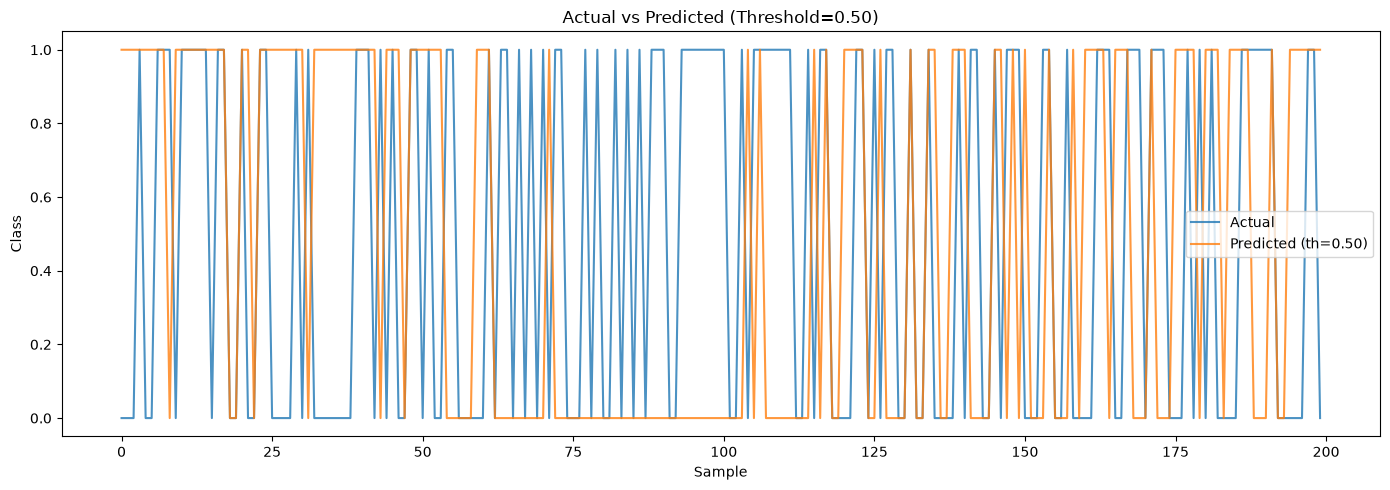

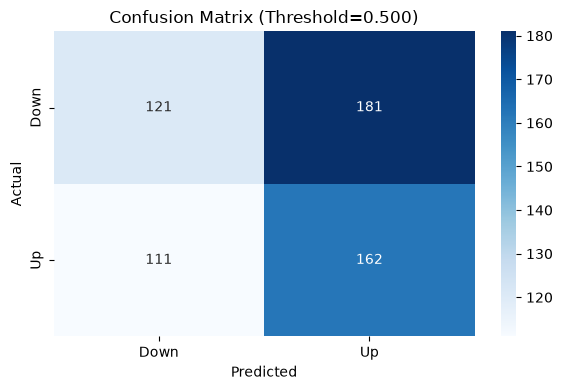

In [35]:
print("Evaluating on test dataset...")
test_scores = evaluator.get_scores(test_loader)
print(f"Test Accuracy: {test_scores['accuracy']:.4f}")
print(f"Test F1: {test_scores['f1']:.4f}")
print(f"Test ROC AUC: {test_scores.get('roc_auc', 0.0):.4f}")

evaluator.plot_predictions(test_loader, n_points=200)
evaluator.plot_confusion_matrix(test_loader)


### MULTI-CLASS CLASSIFICATION (TRADE SIGNAL)
Using `trade_signal` as the target for a 3-class classification problem.

In [36]:
# Map trade signal to 0, 1, 2 for CrossEntropyLoss
full_df["trade_signal_class"] = (full_df["trade_signal"] + 1).astype(int)
target_col_mc = "trade_signal_class"

CustomDataLoader_mc = CustomDataLoader(
    data=full_df,
    feature_cols=feature_cols,
    target_col=target_col_mc,
    sequence_length=30,
    batch_size=64,
    train_length=0.8,
    val_length=0.1,
    scaler=StandardScaler,
    binary_output=True, # We will fix targets manually below
)
loaders_mc = CustomDataLoader_mc.get_loaders()
train_loader_mc = loaders_mc["train"]
val_loader_mc = loaders_mc["validation"]
test_loader_mc = loaders_mc["test"]

# Fix the dataloader targets to be long and 1D for CrossEntropyLoss
for name, loader in loaders_mc.items():
    loader.dataset.tensors = (loader.dataset.tensors[0], loader.dataset.tensors[1].long().squeeze(1))


In [37]:
class LSTMClassifierMultiClass(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.4, num_classes=3):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size, hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=True,
        )
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(dropout / 2),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

# Calculate class weights for imbalance
train_targets_mc = full_df[target_col_mc].iloc[:int(len(full_df)*0.8)].values
class_counts = np.bincount(train_targets_mc)
total_samples = len(train_targets_mc)
class_weights = total_samples / (len(class_counts) * class_counts)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print(f"Class counts: {class_counts}")
print(f"Class weights: {class_weights}")

model_mc = LSTMClassifierMultiClass(
    input_size=len(feature_cols), hidden_size=64, num_layers=2, dropout=0.4, num_classes=3
)
optimizer_mc = optim.Adam(model_mc.parameters(), lr=0.001)
scheduler_mc = ReduceLROnPlateau(optimizer_mc, mode="min", factor=0.5, patience=5)
criterion_mc = nn.CrossEntropyLoss(weight=class_weights_tensor)

trainer_mc = ModelTrainer(
    model=model_mc,
    optimizer=optimizer_mc,
    criterion=criterion_mc,
    device=DEVICE,
    test_data_loader=test_loader_mc,
    train_data_loader=train_loader_mc,
    validation_data_loader=val_loader_mc,
    max_grad_norm=1.0,
)


Class counts: [ 932 2659  997]
Class weights: [1.64091559 0.57515357 1.53393514]


In [38]:
EPOCHS_MC = 50
PATIENCE_MC = 10
best_val_loss_mc = float("inf")
patience_counter_mc = 0
best_model_state_mc = None

for epoch in range(EPOCHS_MC):
    train_loss = trainer_mc.train_epoch()
    val_loss = trainer_mc.validate()
    scheduler_mc.step(val_loss)
    
    # Calculate simple accuracy for logging
    model_mc.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, targets in val_loader_mc:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            outputs = model_mc(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    val_acc = correct / total
    
    cur_lr = optimizer_mc.param_groups[0]["lr"]
    print(f"Epoch {epoch + 1}/{EPOCHS_MC} TrnLoss: {train_loss:.4f} ValLoss: {val_loss:.4f} ValAcc: {val_acc:.4f} LR: {cur_lr:.6f}")
    
    if val_loss < best_val_loss_mc:
        best_val_loss_mc = val_loss
        best_model_state_mc = copy.deepcopy(model_mc.state_dict())
        patience_counter_mc = 0
        print(f"  >> New best (val_loss={best_val_loss_mc:.4f})")
    else:
        patience_counter_mc += 1
        if patience_counter_mc >= PATIENCE_MC:
            print(f"\nEarly stopping at epoch {epoch + 1}")
            break

if best_model_state_mc is not None:
    model_mc.load_state_dict(best_model_state_mc)
    print(f"\nRestored best model (val_loss={best_val_loss_mc:.4f})")


Epoch 1/50 TrnLoss: 1.0329 ValLoss: 1.0864 ValAcc: 0.2496 LR: 0.001000
  >> New best (val_loss=1.0864)
Epoch 2/50 TrnLoss: 0.9988 ValLoss: 1.0844 ValAcc: 0.3159 LR: 0.001000
  >> New best (val_loss=1.0844)
Epoch 3/50 TrnLoss: 0.9937 ValLoss: 1.0861 ValAcc: 0.3124 LR: 0.001000
Epoch 4/50 TrnLoss: 0.9929 ValLoss: 1.0828 ValAcc: 0.3525 LR: 0.001000
  >> New best (val_loss=1.0828)
Epoch 5/50 TrnLoss: 0.9879 ValLoss: 1.0866 ValAcc: 0.2688 LR: 0.001000
Epoch 6/50 TrnLoss: 0.9875 ValLoss: 1.0863 ValAcc: 0.2618 LR: 0.001000
Epoch 7/50 TrnLoss: 0.9822 ValLoss: 1.0880 ValAcc: 0.2513 LR: 0.001000
Epoch 8/50 TrnLoss: 0.9777 ValLoss: 1.0847 ValAcc: 0.3333 LR: 0.001000
Epoch 9/50 TrnLoss: 0.9817 ValLoss: 1.0857 ValAcc: 0.3124 LR: 0.001000
Epoch 10/50 TrnLoss: 0.9731 ValLoss: 1.0918 ValAcc: 0.3700 LR: 0.000500
Epoch 11/50 TrnLoss: 0.9712 ValLoss: 1.0905 ValAcc: 0.3595 LR: 0.000500
Epoch 12/50 TrnLoss: 0.9711 ValLoss: 1.0897 ValAcc: 0.3543 LR: 0.000500
Epoch 13/50 TrnLoss: 0.9667 ValLoss: 1.0880 ValAc


Evaluating on Test Dataset...

Test Classification Report:
              precision    recall  f1-score   support

   Sell (-1)       0.23      0.90      0.36       129
 Nothing (0)       0.59      0.09      0.16       315
     Buy (1)       0.07      0.01      0.01       131

    accuracy                           0.25       575
   macro avg       0.30      0.33      0.18       575
weighted avg       0.39      0.25      0.17       575



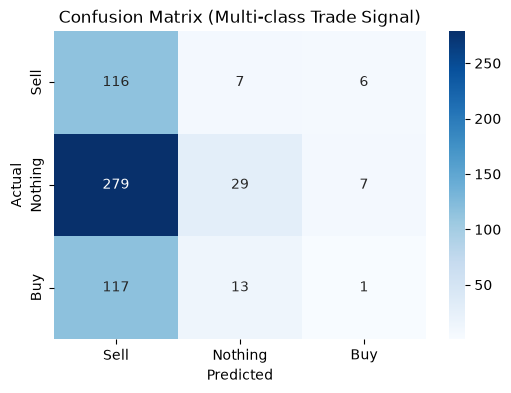

In [39]:
from sklearn.metrics import classification_report, confusion_matrix

def predict_multiclass(model, loader):
    model.eval()
    all_preds = []
    all_targets = []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(DEVICE)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
    return np.array(all_preds), np.array(all_targets)

print("\nEvaluating on Test Dataset...")
test_preds, test_targets = predict_multiclass(model_mc, test_loader_mc)
print("\nTest Classification Report:")
print(classification_report(test_targets, test_preds, labels=[0, 1, 2], target_names=["Sell (-1)", "Nothing (0)", "Buy (1)"]))

plt.figure(figsize=(6, 4))
cm = confusion_matrix(test_targets, test_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Sell", "Nothing", "Buy"], yticklabels=["Sell", "Nothing", "Buy"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Multi-class Trade Signal)")
plt.show()


### PROFIT CALCULATOR
Calculate and plot cumulative profits based on the multi-class trade signals.

In [40]:
class ProfitCalculator:
    def __init__(self, predictions, actual_returns, initial_capital=10000):
        """
        predictions: array of trade signals (-1=Sell, 0=Hold, 1=Buy)
        actual_returns: array of actual numerical returns for the next day
        """
        self.predictions = np.asarray(predictions)
        self.actual_returns = np.asarray(actual_returns)
        self.initial_capital = initial_capital
        
        # Compute period returns: Signal * Actual Return
        # If Sell (-1) and price drops (negative return), you make profit. 
        # If Buy (1) and price rises (positive return), you make profit.
        self.strategy_returns = self.predictions * self.actual_returns
        
        self.cumulative_returns = np.cumprod(1 + self.strategy_returns)
        self.cumulative_profits = self.initial_capital * self.cumulative_returns
        
        # Benchmark (Buy and Hold)
        self.benchmark_returns = self.actual_returns
        self.benchmark_cumulative = np.cumprod(1 + self.benchmark_returns)
        self.benchmark_profits = self.initial_capital * self.benchmark_cumulative
        
    def summary(self):
        total_strategy_return = (self.cumulative_returns[-1] - 1) * 100
        total_benchmark_return = (self.benchmark_cumulative[-1] - 1) * 100
        
        print("=== Profit Summary ===")
        print(f"Initial Capital: ${self.initial_capital:,.2f}")
        print(f"Final Strategy Value: ${self.cumulative_profits[-1]:,.2f} ({total_strategy_return:.2f}%)")
        print(f"Final Buy & Hold Value: ${self.benchmark_profits[-1]:,.2f} ({total_benchmark_return:.2f}%)")
        
        # Calculate max drawdown
        roll_max = np.maximum.accumulate(self.cumulative_profits)
        drawdown = (self.cumulative_profits - roll_max) / roll_max
        max_drawdown = np.min(drawdown) * 100
        print(f"Strategy Max Drawdown: {max_drawdown:.2f}%")
        
    def plot(self):
        plt.figure(figsize=(12, 6))
        plt.plot(self.cumulative_profits, label="Strategy Profits", linewidth=2)
        plt.plot(self.benchmark_profits, label="Buy & Hold Profits", linestyle="--", alpha=0.7)
        plt.title("Cumulative Profits: Strategy vs Buy & Hold")
        plt.xlabel("Trade Steps (Days)")
        plt.ylabel("Portfolio Value ($)")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()


=== Profit Summary ===
Initial Capital: $10,000.00
Final Strategy Value: $9,982.55 (-0.17%)
Final Buy & Hold Value: $10,464.20 (4.64%)
Strategy Max Drawdown: -6.07%


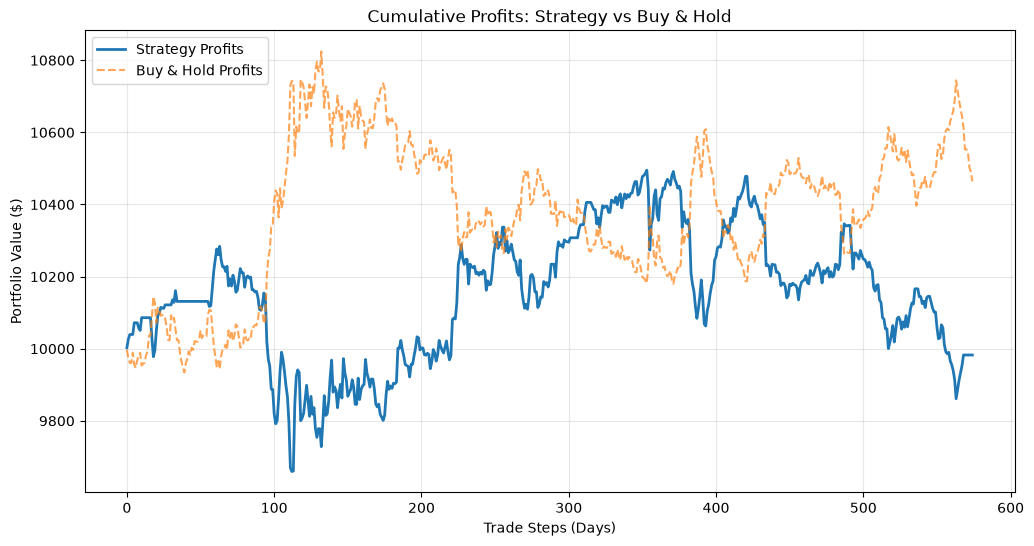

In [41]:
# Extract test indices to get the corresponding actual numerical returns
test_mask = CustomDataLoader_mc.sequence_indices >= CustomDataLoader_mc.val_end
test_idx = CustomDataLoader_mc.sequence_indices[test_mask]

# Map predictions back from (0, 1, 2) to (-1, 0, 1) for profit calculation
strategy_signals = test_preds - 1

# Get the actual percentage changes (returns) corresponding to the test set targets
# Using full_df['DEXINUS'].pct_change() because that is how trade_signal was defined
actual_returns_test = full_df["DEXINUS"].pct_change(periods=1).values[test_idx]

calculator = ProfitCalculator(predictions=strategy_signals, actual_returns=actual_returns_test, initial_capital=10000)
calculator.summary()
calculator.plot()



Evaluating on val Dataset...

val Classification Report:
              precision    recall  f1-score   support

   Sell (-1)       0.25      0.77      0.38       132
 Nothing (0)       0.61      0.31      0.42       293
     Buy (1)       0.36      0.05      0.09       148

    accuracy                           0.35       573
   macro avg       0.41      0.38      0.30       573
weighted avg       0.47      0.35      0.32       573



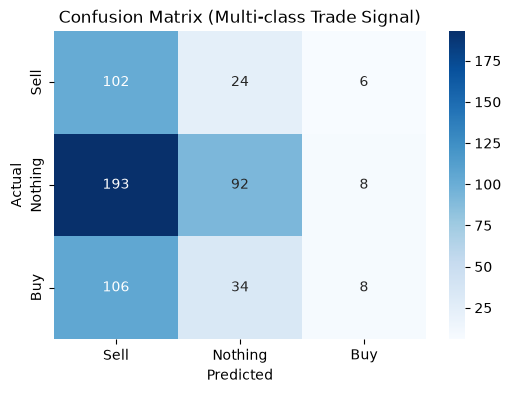

In [43]:
print("\nEvaluating on val Dataset...")
val_preds, val_targets = predict_multiclass(model_mc, val_loader_mc)
print("\nval Classification Report:")
print(classification_report(val_targets, val_preds, labels=[0, 1, 2], target_names=["Sell (-1)", "Nothing (0)", "Buy (1)"]))

plt.figure(figsize=(6, 4))
cm = confusion_matrix(val_targets, val_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Sell", "Nothing", "Buy"], yticklabels=["Sell", "Nothing", "Buy"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Multi-class Trade Signal)")
plt.show()


=== Profit Summary ===
Initial Capital: $10,000.00
Final Strategy Value: $9,295.83 (-7.04%)
Final Buy & Hold Value: $11,137.40 (11.37%)
Strategy Max Drawdown: -14.17%


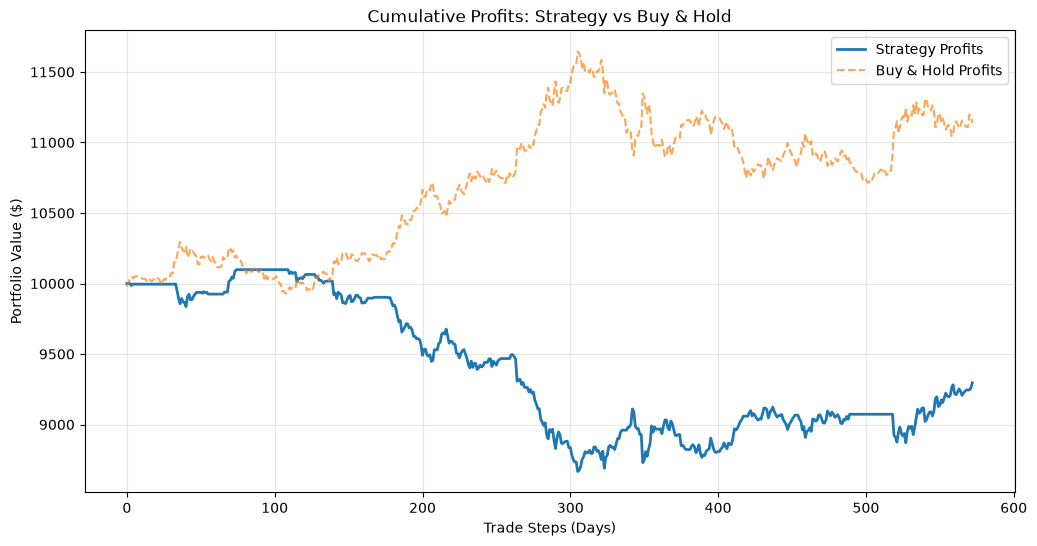

In [48]:
val_mask = (
    (CustomDataLoader_mc.sequence_indices >= CustomDataLoader_mc.train_end)
    & (CustomDataLoader_mc.sequence_indices < CustomDataLoader_mc.val_end)
)
val_idx = CustomDataLoader_mc.sequence_indices[val_mask]

strategy_signals = val_preds - 1
actual_returns_val = full_df["DEXINUS"].pct_change().to_numpy()[val_idx]

calculator = ProfitCalculator(
    predictions=strategy_signals,
    actual_returns=actual_returns_val,
    initial_capital=10000,
)
calculator.summary()
calculator.plot()

### TRAINING AND PREDICTING VAL DATASET